# 03 · Supervised models, judged on later months

Ways to rank payments for review, fitted on the training months (days 0–119), chosen on the
validation months (120–149) and scored **once** on the test months (150 onwards):

| Model | What it is |
|---|---|
| Rules | A stand-in for today's rules (`config.RULES`), written before any model was fitted |
| Logistic regression | Numeric fields and phase-2 features, missing flags, standardized |
| Gradient boosting | LightGBM on the phase-2 features and the raw fields, **without** the provider's `V` columns |
| Gradient boosting + V | The same with the 339 `V` columns |
| … , tuned | The same two with parameters from an Optuna search inside the training months |

**The primary model is the boosting model whose decisions cost least on the validation months**: each
candidate is calibrated there, gets its decline threshold there (the phase-5 procedure), and its
expected-cost policy is priced there. The test months only report.

With about 3.5% fraud, ROC AUC flatters every model, so the headline metrics are PR-AUC and
**recall at review capacity**: the share of fraud (and of fraud dollars) in the top 1.5% of scores,
the payments the team can actually look at.

In [1]:
import sys
from pathlib import Path


def _project_root() -> Path:
    here = Path.cwd().resolve()
    for p in (here, *here.parents):
        if (p / "src" / "fraudrisk" / "__init__.py").exists():
            return p
    raise FileNotFoundError("run from inside the project folder")


sys.path.insert(0, str(_project_root() / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from fraudrisk import config, data, features, model, policy
from fraudrisk.records import show_verdict, write_metrics

SOURCE = data.source()
# the synthetic CI run only checks that the code runs: a faster learning rate keeps it short
GBM_PARAMS = {} if SOURCE == "real" else {"learning_rate": 0.2, "num_leaves": 15}
GBM_ROUNDS = 2000 if SOURCE == "real" else 150
TUNING_TRIALS = 40 if SOURCE == "real" else 3
con = data.connect()
features.build(con)
F = features.frame(con)
uid = con.sql("SELECT TransactionID, uid FROM base").df()
raw = con.sql(f"SELECT {', '.join(model.raw_columns(with_v=False))} FROM tx").df()
print(SOURCE, F.shape, raw.shape)

real (590540, 21) (590540, 75)


## 1. Tune, inside the training months

An Optuna (TPE) search over tree shape and regularization: 40 trials, each fitted on days 0–89 and
scored by PR-AUC on days 90–119, with the defaults run first as trial 0. Neither the validation nor the
test months are touched. The search uses the model without the `V` columns (faster); its best
parameters are then fitted with and without `V`. Trials use a learning rate of 0.1 to keep each fit
short; the final models use 0.05.

In [2]:
d_nov = model.design(F, raw, with_v=False)
del raw
d_v = model.with_v(d_nov, con)
assert (d_nov.transaction_id == d_v.transaction_id).all()
y, split, amount = d_nov.y, d_nov.split, d_nov.amount
va, te = split == "valid", split == "test"

rule_frame = F.merge(d_nov.X[[]].assign(TransactionID=d_nov.transaction_id), on="TransactionID")
rule_frame = rule_frame.merge(con.sql("SELECT TransactionID, ProductCD, TransactionAmt FROM tx").df(), on="TransactionID")
rule_frame = rule_frame.set_index("TransactionID").loc[d_nov.transaction_id].reset_index()
scores = {"Rules": model.rules_score(rule_frame)}

tuning = model.tune_lightgbm(d_nov, n_trials=TUNING_TRIALS)
TUNED_PARAMS = {**GBM_PARAMS, **tuning["best_params"]}
print(f"PR-AUC on days {model.TUNE_START}-119: defaults {tuning['default_value']:.4f}, best trial {tuning['best_value']:.4f}")
tuning["trials"].sort_values("value", ascending=False).head(8).round(4)

PR-AUC on days 90-119: defaults 0.5858, best trial 0.6293


,number,value,params_bagging_fraction,params_cat_smooth,params_feature_fraction,params_lambda_l2,params_min_child_samples,params_num_leaves,user_attrs_rounds
26,26,0.6293,0.9064,1.2857,0.7870,0.0171,63,231,988
25,25,0.6267,0.9595,1.4357,0.9300,0.2474,71,248,993
33,33,0.6256,0.9237,1.4734,0.9781,0.2021,21,225,876
21,21,0.6251,0.9273,2.7006,0.9932,0.0518,25,195,940
38,38,0.6244,0.9588,1.6110,0.8810,0.0686,22,192,994
35,35,0.6229,0.9575,1.0888,0.9783,0.3624,22,212,751
37,37,0.6228,0.8926,2.5600,0.9129,0.0278,50,241,1000
28,28,0.6218,0.9617,1.9224,0.7941,0.0989,85,168,1000


## 2. Fit

In [3]:
logit = model.fit_logistic(d_nov)
scores["Logistic regression"] = logit(d_nov.X)

In [4]:
gbm = model.fit_lightgbm(d_nov, GBM_PARAMS, GBM_ROUNDS)
scores["Gradient boosting"] = gbm.predict(d_nov.X, num_iteration=gbm.best_iteration)
print("rounds (no V):", gbm.best_iteration)

rounds (no V): 1043


In [5]:
gbm_v = model.fit_lightgbm(d_v, GBM_PARAMS, GBM_ROUNDS)
scores["Gradient boosting + V"] = gbm_v.predict(d_v.X, num_iteration=gbm_v.best_iteration)
print("rounds (+V):", gbm_v.best_iteration)

rounds (+V): 1141


In [6]:
gbm_t = model.fit_lightgbm(d_nov, TUNED_PARAMS, GBM_ROUNDS)
scores["Gradient boosting, tuned"] = gbm_t.predict(d_nov.X, num_iteration=gbm_t.best_iteration)
print("rounds (tuned):", gbm_t.best_iteration)

rounds (tuned): 1866


In [7]:
gbm_tv = model.fit_lightgbm(d_v, TUNED_PARAMS, GBM_ROUNDS)
scores["Gradient boosting + V, tuned"] = gbm_tv.predict(d_v.X, num_iteration=gbm_tv.best_iteration)
print("rounds (+V, tuned):", gbm_tv.best_iteration)
BOOSTERS = {"Gradient boosting": (gbm, d_nov, GBM_PARAMS), "Gradient boosting + V": (gbm_v, d_v, GBM_PARAMS),
            "Gradient boosting, tuned": (gbm_t, d_nov, TUNED_PARAMS),
            "Gradient boosting + V, tuned": (gbm_tv, d_v, TUNED_PARAMS)}

rounds (+V, tuned): 585


## 3. Validation months: choose the model by the cost of its decisions

Each boosting model is calibrated on the validation months, gets the decline threshold that keeps
good-customer declines within the rules' rate there, and its expected-cost policy is priced there.
The cheapest becomes the primary model. Test-month costs are computed the same way and only reported.

In [8]:
C = policy.Costs()
day = d_nov.day


def rules_actions(mask, c):
    hits = np.floor(scores["Rules"][mask])
    a = policy.review_top(np.where(hits >= 1, scores["Rules"][mask], -np.inf), day[mask], c,
                          decline=hits >= config.RULES_DECLINE_HITS)
    a[(a == policy.REVIEW) & (hits < 1)] = policy.APPROVE
    return a


rules_valid = policy.realized(rules_actions(va, C), y[va], amount[va], C)
selection = {}
for name in BOOSTERS:
    s = scores[name]
    p = model.calibrate(s[va], y[va])(s)
    tau = policy.decline_threshold(p[va], amount[va], day[va], y[va], C, rules_valid["good_decline_rate"])
    selection[name] = {
        "valid_pr_auc": model.evaluate(s[va], y[va], amount[va])["pr_auc"],
        "decline_threshold": tau,
        "valid_policy_cost_per_1000": policy.realized(policy.choose(p[va], amount[va], day[va], C, tau),
                                                      y[va], amount[va], C)["cost_per_1000"],
        "test_policy_cost_per_1000": policy.realized(policy.choose(p[te], amount[te], day[te], C, tau),
                                                     y[te], amount[te], C)["cost_per_1000"],
    }
selection = pd.DataFrame(selection).T
PRIMARY = selection["valid_policy_cost_per_1000"].idxmin()
booster, D, PRIMARY_PARAMS = BOOSTERS[PRIMARY]
valid = pd.DataFrame({k: model.evaluate(s[va], y[va], amount[va]) for k, s in scores.items()}).T
print("primary model:", PRIMARY)
selection.round(4)

primary model: Gradient boosting, tuned


,valid_pr_auc,decline_threshold,valid_policy_cost_per_1000,test_policy_cost_per_1000
Gradient boosting,0.6095,0.94,3369.6314,3650.9517
Gradient boosting + V,0.6238,0.94,3219.1753,3440.7583
"Gradient boosting, tuned",0.6567,0.94,3174.0620,3495.6621
"Gradient boosting + V, tuned",0.6442,0.95,3287.4380,3451.0464


## 4. Test months, scored once

In [9]:
test = pd.DataFrame({k: model.evaluate(s[te], y[te], amount[te]) for k, s in scores.items()}).T
groups = uid.set_index("TransactionID").loc[d_nov.transaction_id, "uid"].fillna(
    pd.Series(d_nov.transaction_id.astype(str), index=uid.set_index("TransactionID").loc[d_nov.transaction_id].index)).to_numpy()
ci = {k: model.bootstrap(scores[k][te], y[te], amount[te], groups[te]) for k in ("Rules", PRIMARY)}
test[["pr_auc", "roc_auc", "recall_at_capacity", "dollar_recall_at_capacity", "precision_at_capacity"]].round(3)

,pr_auc,roc_auc,recall_at_capacity,dollar_recall_at_capacity,precision_at_capacity
Rules,0.042,0.512,0.020,0.136,0.045
Logistic regression,0.249,0.816,0.191,0.120,0.443
Gradient boosting,0.526,0.907,0.322,0.260,0.746
Gradient boosting + V,0.552,0.909,0.342,0.265,0.792
"Gradient boosting, tuned",0.562,0.897,0.352,0.270,0.815
"Gradient boosting + V, tuned",0.568,0.906,0.357,0.262,0.827


## 5. How much comes from customers already known as fraud?

Phase 1 showed labels are shared within a customer. Split the test fraud by whether the customer
already had a fraud label in the training months, and measure recall at capacity within each group.
The second group is the honest test of whether the model recognizes *fraud*, not *fraudsters*.

In [10]:
known = set(uid.loc[uid["TransactionID"].isin(d_nov.transaction_id[(split == "train") & (y == 1)]), "uid"].dropna())
seen = np.array([g in known for g in groups])
k = max(1, int(round(config.REVIEW_CAPACITY * te.sum())))
by_group = {}
for name in ("Rules", PRIMARY):
    s = scores[name][te]
    flagged = np.zeros(te.sum(), bool)
    flagged[np.argsort(-s, kind="stable")[:k]] = True
    yt, st = y[te], seen[te]
    by_group[name] = {"customer already labelled fraud": float(flagged[(yt == 1) & st].mean()) if ((yt == 1) & st).any() else None,
                      "new to fraud": float(flagged[(yt == 1) & ~st].mean()) if ((yt == 1) & ~st).any() else None}
share_known = float(seen[te][y[te] == 1].mean())
print(f"share of test fraud from customers already labelled fraud in training: {share_known:.0%}")
pd.DataFrame(by_group).round(3)

share of test fraud from customers already labelled fraud in training: 16%


,Rules,"Gradient boosting, tuned"
customer already labelled fraud,0.016,0.498
new to fraud,0.020,0.324


## 6. Calibration

Phase 5 turns scores into decisions by expected cost, which needs probabilities. An isotonic map is
fitted on the validation months and checked on the test months.

In [11]:
to_prob = model.calibrate(scores[PRIMARY][va], y[va])
prob = to_prob(scores[PRIMARY])
calib = model.calibration_table(prob[te], y[te])
from sklearn.metrics import brier_score_loss
brier = {"calibrated": brier_score_loss(y[te], prob[te]), "raw": brier_score_loss(y[te], scores[PRIMARY][te]),
         "base rate only": brier_score_loss(y[te], np.full(te.sum(), y[split == "train"].mean()))}
print({k: round(v, 5) for k, v in brier.items()})
calib.round(4)

{'calibrated': 0.02132, 'raw': 0.02355, 'base rate only': 0.03355}


,bin,predicted,observed,n
0,0,0.0027,0.0028,9243
1,1,0.0029,0.0035,9243
2,2,0.0031,0.0048,9242
3,3,0.0035,0.0070,9243
4,4,0.0044,0.0062,9243
5,5,0.0063,0.0101,9242
6,6,0.0099,0.0123,9243
7,7,0.0176,0.0177,9242
8,8,0.0294,0.0287,9243
9,9,0.2786,0.2546,9243


## 7. What drives the score, and what a reviewer sees

In [12]:
imp = model.global_importance(booster, D.X[te])
reasons = model.reason_codes(booster, D.X[te].iloc[np.argsort(-scores[PRIMARY][te], kind="stable")[:k]])
top_reasons = reasons["reason_1"].value_counts(normalize=True).head(8)
imp.head(15).round(4)

C13              0.5881
C5               0.5175
D4_date          0.4997
D1_date          0.4471
C14              0.4103
C1               0.3476
log_amount       0.3424
card2_freq       0.2858
card1_freq       0.2847
P_emaildomain    0.2722
card6            0.2499
amount_cents     0.2204
dist1            0.2185
addr1_freq       0.2134
C11              0.2112
dtype: float64

In [13]:
top_reasons.round(3)

reason_1
C1            0.547
C14           0.224
C13           0.043
log_amount    0.033
C9            0.026
DeviceInfo    0.025
C6            0.021
card1_freq    0.018
Name: proportion, dtype: float64

## 8. Figure

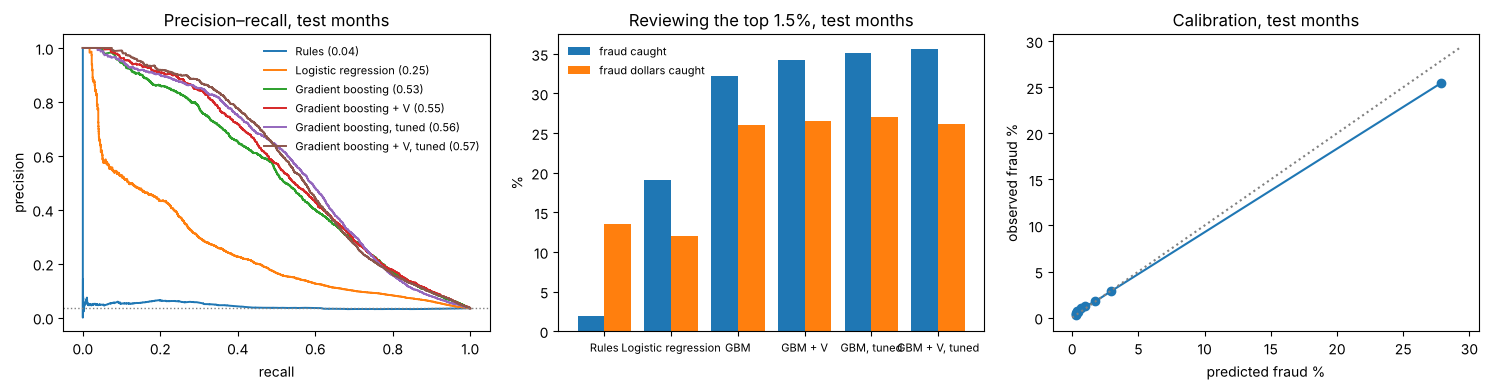

In [14]:
from sklearn.metrics import precision_recall_curve

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
ax = axes[0]
for name, s in scores.items():
    p, r, _ = precision_recall_curve(y[te], s[te])
    ax.plot(r, p, label=f"{name} ({test.loc[name, 'pr_auc']:.2f})", lw=1.4)
ax.axhline(y[te].mean(), color="grey", ls=":", lw=1)
ax.set(title="Precision–recall, test months", xlabel="recall", ylabel="precision")
ax.legend(fontsize=8, frameon=False)
ax = axes[1]
x = np.arange(len(test))
ax.bar(x - 0.2, 100 * test["recall_at_capacity"], 0.4, label="fraud caught")
ax.bar(x + 0.2, 100 * test["dollar_recall_at_capacity"], 0.4, label="fraud dollars caught")
ax.set_xticks(x, [n.replace("Gradient boosting", "GBM") for n in test.index], fontsize=8)
ax.set(title=f"Reviewing the top {config.REVIEW_CAPACITY:.1%}, test months", ylabel="%")
ax.legend(fontsize=8, frameon=False)
ax = axes[2]
ax.plot(100 * calib["predicted"], 100 * calib["observed"], marker="o")
lim = 100 * max(calib["predicted"].max(), calib["observed"].max()) * 1.05
ax.plot([0, lim], [0, lim], color="grey", ls=":")
ax.set(title="Calibration, test months", xlabel="predicted fraud %", ylabel="observed fraud %")
fig.tight_layout()
data.savefig(fig, "03_model", SOURCE)

## 9. Save scores for phases 4–6 (real data only; never committed) and the record

In [15]:
if SOURCE == "real":
    out = data.PARQUET.parent / "scores.parquet"
    pd.DataFrame({"TransactionID": d_nov.transaction_id, "split": split, "day": d_nov.day, "isFraud": y,
                  "amount": amount, "uid": groups, "score": scores[PRIMARY], "prob": prob,
                  "rules_score": scores["Rules"]}).to_parquet(out)
    print("wrote", out.relative_to(data.ROOT).as_posix())


def _rec(df):
    return {k: {kk: float(vv) for kk, vv in r.items()} for k, r in df.iterrows()}


record = {
    "primary_model": PRIMARY,
    "primary_params": {k: (int(v) if isinstance(v, (int, np.integer)) else float(v)) for k, v in PRIMARY_PARAMS.items()},
    "tuning": {"trials": TUNING_TRIALS, "inner_split_day": model.TUNE_START,
               "default_pr_auc": float(tuning["default_value"]), "best_pr_auc": float(tuning["best_value"]),
               "best_params": {k: (int(v) if isinstance(v, (int, np.integer)) else float(v))
                               for k, v in tuning["best_params"].items()}},
    "selection": {k: {kk: float(vv) for kk, vv in r.items()} for k, r in selection.iterrows()},
    "boosting_rounds": {k: int(b.best_iteration) for k, (b, _, _) in BOOSTERS.items()},
    "valid": _rec(valid), "test": _rec(test),
    "test_ci": {k: {m: list(v) for m, v in c.items()} for k, c in ci.items()},
    "known_customers": {"share_of_test_fraud": share_known, "recall_at_capacity": by_group},
    "calibration": {"brier": brier, "table": calib.to_dict(orient="records")},
    "importance_top15": {k: float(v) for k, v in imp.head(15).items()},
    "top_reason_share": {k: float(v) for k, v in top_reasons.items()},
}
write_metrics("03_model", record, SOURCE)

wrote data/interim/scores.parquet


In [16]:
t, r = test.loc[PRIMARY], test.loc["Rules"]
sel = selection.sort_values("valid_policy_cost_per_1000")
runner = sel.index[1]
test_best = selection["test_policy_cost_per_1000"].idxmin()
c = record["test_ci"][PRIMARY]
bg = by_group[PRIMARY]
show_verdict(
    "Verdict: phase 3, supervised models",
    [
        f"**Tuning**: {TUNING_TRIALS} Optuna trials inside the training months reached PR-AUC {tuning['best_value']:.3f} on "
        f"days {model.TUNE_START}–119, against {tuning['default_value']:.3f} for the defaults.",
        f"**{PRIMARY} is the primary model**: its decisions cost least on the validation months "
        f"(${sel.loc[PRIMARY, 'valid_policy_cost_per_1000']:,.0f} per 1,000 payments; runner-up {runner} "
        f"${sel.loc[runner, 'valid_policy_cost_per_1000']:,.0f}). On the test months the same procedure costs "
        f"${sel.loc[PRIMARY, 'test_policy_cost_per_1000']:,.0f} for it and ${sel.loc[runner, 'test_policy_cost_per_1000']:,.0f} "
        f"for the runner-up" + (f"; the cheapest on the test months is {test_best}, so the validation margin of "
                                f"${sel.loc[runner, 'valid_policy_cost_per_1000'] - sel.loc[PRIMARY, 'valid_policy_cost_per_1000']:,.0f} "
                                "did not hold: differences this small are within noise." if test_best != PRIMARY else ".")
        + f" On the test months it "
        f"finds **{t['recall_at_capacity']:.0%} of fraud and {t['dollar_recall_at_capacity']:.0%} of fraud dollars** in the top "
        f"{config.REVIEW_CAPACITY:.1%} of scores [recall 95% interval {c['recall_at_capacity'][0]:.0%}–{c['recall_at_capacity'][1]:.0%}], "
        f"against {r['recall_at_capacity']:.0%} and {r['dollar_recall_at_capacity']:.0%} for the rules; PR-AUC "
        f"{t['pr_auc']:.3f} vs {r['pr_auc']:.3f}.",
        (f"**The rules stand-in is close to chance on this data** (ROC AUC {r['roc_auc']:.2f}): it was written without "
         "looking, and the merchant's real rules are not in the data. "
         if r["roc_auc"] < 0.6 else "")
        + f"**The fair baseline is logistic regression**: {test.loc['Logistic regression', 'recall_at_capacity']:.0%} of fraud at "
        f"capacity, PR-AUC {test.loc['Logistic regression', 'pr_auc']:.3f}. Gradient boosting's gain over it is the "
        "interactions and the categorical fields a linear model cannot use.",
        f"**{share_known:.0%} of test fraud comes from customers already labelled fraud** in the training months. The model "
        f"flags {bg['customer already labelled fraud'] or 0:.0%} of that fraud and {bg['new to fraud'] or 0:.0%} of fraud from "
        "customers new to fraud; the second number is the one that measures recognizing fraud rather than fraudsters.",
        f"**Calibrated probabilities** (isotonic, fitted on validation): Brier {brier['calibrated']:.4f} against "
        f"{brier['base rate only']:.4f} for the base rate alone, so phase 5 can price decisions with them.",
        "**Most common top reason among flagged payments**: " + ", ".join(f"`{k}` ({v:.0%})" for k, v in top_reasons.head(3).items()) + ".",
    ],
    "Phase 4 asks what an anomaly detector that never sees a fraud label adds to this.",
)

### Verdict: phase 3, supervised models

1. **Tuning**: 40 Optuna trials inside the training months reached PR-AUC 0.629 on days 90–119, against 0.586 for the defaults.
2. **Gradient boosting, tuned is the primary model**: its decisions cost least on the validation months (\$3,174 per 1,000 payments; runner-up Gradient boosting + V \$3,219). On the test months the same procedure costs \$3,496 for it and \$3,441 for the runner-up; the cheapest on the test months is Gradient boosting + V, so the validation margin of \$45 did not hold: differences this small are within noise. On the test months it finds **35% of fraud and 27% of fraud dollars** in the top 1.5% of scores [recall 95% interval 32%–38%], against 2% and 14% for the rules; PR-AUC 0.562 vs 0.042.
3. **The rules stand-in is close to chance on this data** (ROC AUC 0.51): it was written without looking, and the merchant's real rules are not in the data. **The fair baseline is logistic regression**: 19% of fraud at capacity, PR-AUC 0.249. Gradient boosting's gain over it is the interactions and the categorical fields a linear model cannot use.
4. **16% of test fraud comes from customers already labelled fraud** in the training months. The model flags 50% of that fraud and 32% of fraud from customers new to fraud; the second number is the one that measures recognizing fraud rather than fraudsters.
5. **Calibrated probabilities** (isotonic, fitted on validation): Brier 0.0213 against 0.0336 for the base rate alone, so phase 5 can price decisions with them.
6. **Most common top reason among flagged payments**: `C1` (55%), `C14` (22%), `C13` (4%).

**Next:** Phase 4 asks what an anomaly detector that never sees a fraud label adds to this.